# Исследование датасета стоимости недвижимости в Турции

# 1. Исследование данных (EDA)

На этом этапе модель ещё не обучается. Задача — понять, что находится в датасете, какие признаки доступны и какие проблемы качества данных нужно учитывать.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    median_absolute_error
)
from lightgbm import LGBMRegressor

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
BASE_DIR = Path.cwd()
FILE_NAME = BASE_DIR / "real_estate_data_ru_FINAL2.csv"

df = pd.read_csv(FILE_NAME, sep=";", low_memory=False)

print("Файл:", FILE_NAME)
print("Размер исходного набора:", df.shape)
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))

Файл: C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\outputs\real_estate_ml_project\real_estate_data_ru_FINAL2.csv
Размер исходного набора: (403487, 17)
Количество строк: 403487
Количество столбцов: 17


## 1.1 Первичный просмотр

In [2]:
display(df.head())
display(df.sample(5, random_state=RANDOM_STATE))
df.info()

,идентификатор,тип_недвижимости,подтип,дата_начала,дата_окончания,тип_объявления,дней_на_рынке,возраст_здания,всего_этажей,этаж,комнаты,площадь_м2,адрес,мебель,тип_отопления,цена,валюта
0,1,Жилая недвижимость,Резиденция,12.10.2018,01.09.2019,Аренда,30,Новое здание,20 и более,2,2+1,90.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,3500.0,Турецкая лира
1,2,Жилая недвижимость,Квартира,2/13/19,NaN,Продажа,14,Новое здание,20 и более,20 ve üzeri,1+0,43.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,490000.0,Турецкая лира
2,3,Жилая недвижимость,Квартира,10.09.2018,11.08.2018,Продажа,30,Новое здание,1,Yüksek Giriş,2+1,NaN,Текирдаг/Чорлу/Решадийе,NaN,Фанкойл,155000.0,Турецкая лира
3,4,Жилая недвижимость,Резиденция,09.10.2018,10.10.2018,Продажа,30,3,20 и более,20 ve üzeri,6+1,450.0,Стамбул/Бешикташ/Левент,NaN,Фанкойл,32500000.0,Турецкая лира
4,5,Жилая недвижимость,Резиденция,12.10.2018,01.09.2019,Продажа,30,Новое здание,20 и более,2,2+1,90.0,Стамбул/Картал/Кордонбойу,NaN,Фанкойл,1450000.0,Турецкая лира


,идентификатор,тип_недвижимости,подтип,дата_начала,дата_окончания,тип_объявления,дней_на_рынке,возраст_здания,всего_этажей,этаж,комнаты,площадь_м2,адрес,мебель,тип_отопления,цена,валюта
60623,60624,Жилая недвижимость,Квартира,11/20/18,2/23/19,Продажа,95,6-10,5,1,2+1,120.0,Анталья/Аланйа/Оба,NaN,Кондиционер,240000.0,Турецкая лира
401384,401385,Жилая недвижимость,Отдельный дом,11/27/18,02.01.2019,Продажа,66,NaN,NaN,NaN,5+1,350.0,Мугла/Бодрум/Гюндоган,NaN,NaN,3850000.0,Турецкая лира
207138,207139,Жилая недвижимость,Квартира,12.08.2018,02.04.2019,Продажа,58,Новое здание,5,3,2+1,80.0,Маниса/Йунусемре/Мурадийе,NaN,Газовый котёл,120000.0,Турецкая лира
51585,51586,Жилая недвижимость,Квартира,01.11.2019,NaN,Продажа,47,Новое здание,5,Kot 1,1+1,45.0,Стамбул/Кагытхане/Емнийет Евлери,NaN,Кондиционер,185000.0,Турецкая лира
168182,168183,Жилая недвижимость,Квартира,11/24/18,NaN,Продажа,95,Новое здание,4,1,3+2,130.0,Стамбул/Санджактепе/Йенидоган,NaN,Газовый котёл,418000.0,Турецкая лира


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   идентификатор     403487 non-null  int64  
 1   тип_недвижимости  403487 non-null  object 
 2   подтип            403487 non-null  object 
 3   дата_начала       403487 non-null  object 
 4   дата_окончания    266298 non-null  object 
 5   тип_объявления    403487 non-null  object 
 6   дней_на_рынке     403487 non-null  int64  
 7   возраст_здания    376097 non-null  object 
 8   всего_этажей      375466 non-null  object 
 9   этаж              368191 non-null  object 
 10  комнаты           403487 non-null  object 
 11  площадь_м2        257481 non-null  float64
 12  адрес             403487 non-null  object 
 13  мебель            0 non-null       float64
 14  тип_отопления     375517 non-null  object 
 15  цена              402772 non-null  float64
 16  валюта            40

## 1.2 Основные категории и валюты

In [3]:
print("Тип объявления:")
display(df["тип_объявления"].value_counts(dropna=False))

print("Тип недвижимости:")
display(df["тип_недвижимости"].value_counts(dropna=False).head(10))

print("Валюта:")
display(df["валюта"].value_counts(dropna=False))

Тип объявления:


тип_объявления
Продажа    287009
Аренда     114236
3            2242
Name: count, dtype: int64

Тип недвижимости:


тип_недвижимости
Жилая недвижимость    403487
Name: count, dtype: int64

Валюта:


валюта
Турецкая лира      400677
Евро                  922
NaN                   715
Фунт стерлингов       621
Доллар США            552
Name: count, dtype: int64

Отдельно проверили валюту, потому что цену в евро, долларах, фунтах и лирах нельзя напрямую сравнивать как одно числовое значение. Поэтому на этапе формирования модельной выборки оставляем единую валюту — турецкую лиру».

## 1.3 Числовые признаки

In [4]:
numeric_cols_eda = ["цена", "площадь_м2", "дней_на_рынке"]
display(df[numeric_cols_eda].describe().T)

,count,mean,std,min,25%,50%,75%,max
цена,402772.0,354641.661933,4.809503e+06,-250.0,2500.0,199000.0,342000.0,2.000000e+09
площадь_м2,257481.0,279.349094,9.429195e+03,1.0,85.0,110.0,140.0,9.482350e+05
дней_на_рынке,403487.0,57.022739,4.435893e+01,0.0,29.0,40.0,90.0,1.800000e+02


Смотрим минимум, максимум, среднее и медиану. Особенно важна разница между средним и медианой: она позволяет заметить сильную асимметрию и возможные выбросы

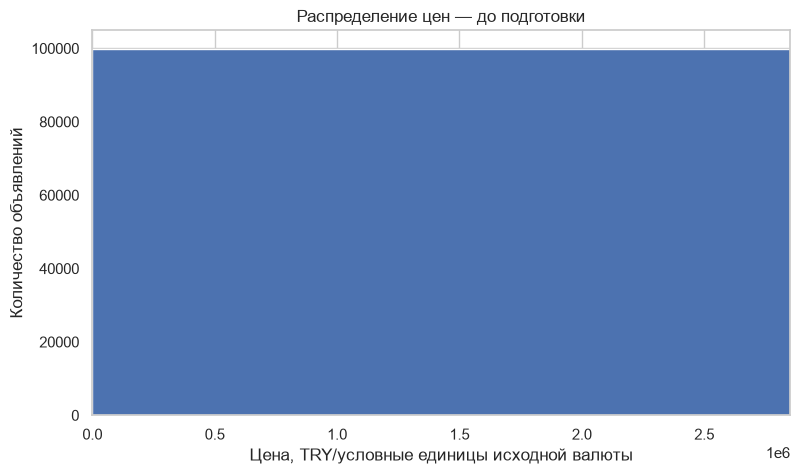

In [5]:
price_all = pd.to_numeric(df["цена"], errors="coerce").dropna()

plt.figure(figsize=(9, 5))
plt.hist(price_all.sample(min(100000, len(price_all)), random_state=RANDOM_STATE), bins=80)
plt.xlim(0, price_all.quantile(0.99))
plt.title("Распределение цен — до подготовки")
plt.xlabel("Цена, TRY/условные единицы исходной валюты")
plt.ylabel("Количество объявлений")
plt.show()

На графике видно, что распределение цен сильно скошено вправо: основная масса объектов находится в относительно меньшем диапазоне, а небольшая часть объектов имеет очень большие значения. Поэтому дальше я отдельно рассматриваю логарифмирование целевой переменной

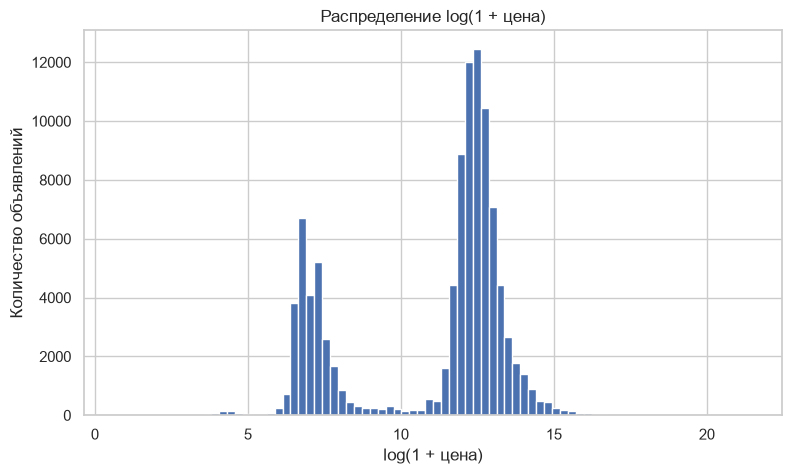

In [6]:
positive_price = price_all[price_all > 0]
log_price = np.log1p(positive_price)

plt.figure(figsize=(9, 5))
plt.hist(log_price.sample(min(100000, len(log_price)), random_state=RANDOM_STATE), bins=80)
plt.title("Распределение log(1 + цена)")
plt.xlabel("log(1 + цена)")
plt.ylabel("Количество объявлений")
plt.show()

Логарифмирование не меняет порядок объектов, но сжимает большие значения. Это уменьшает влияние экстремально дорогих объектов при обучении и делает распределение более удобным для регрессии. После прогнозирования я выполняю обратное преобразование `expm1`

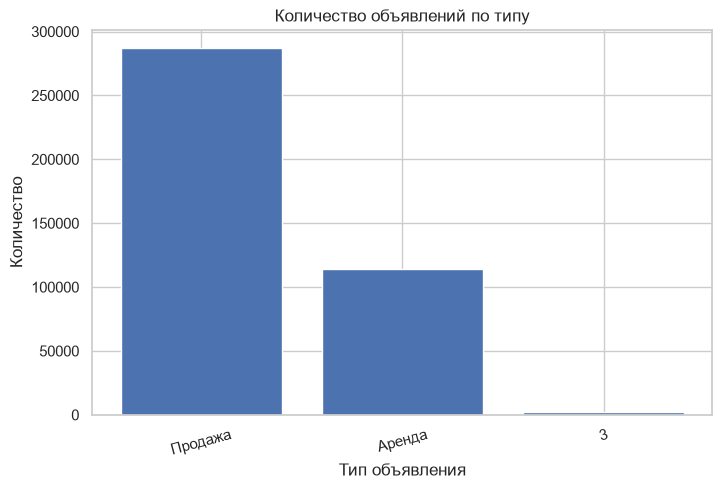

In [7]:
type_counts = df["тип_объявления"].value_counts(dropna=False)
plt.figure(figsize=(8, 5))
plt.bar(type_counts.index.astype(str), type_counts.values)
plt.title("Количество объявлений по типу")
plt.xlabel("Тип объявления")
plt.ylabel("Количество")
plt.xticks(rotation=15)
plt.show()

На исходном этапе обнаружено некорректное значение `3` в признаке `тип_объявления`.

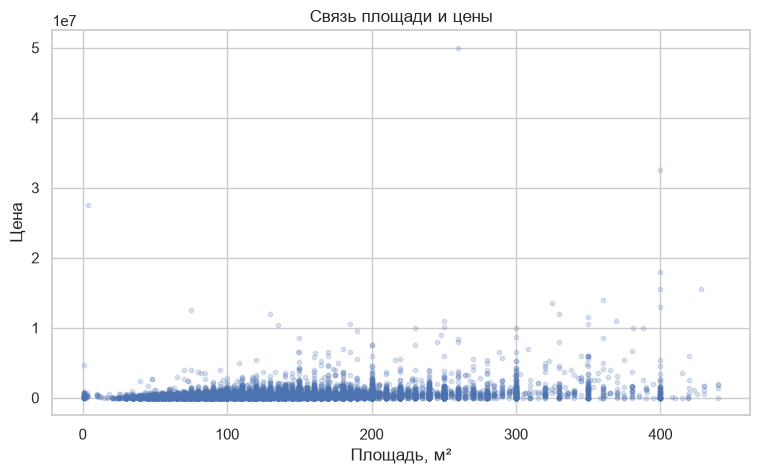

In [8]:
plot_df = df[["площадь_м2", "цена"]].copy()
plot_df["площадь_м2"] = pd.to_numeric(plot_df["площадь_м2"], errors="coerce")
plot_df["цена"] = pd.to_numeric(plot_df["цена"], errors="coerce")
plot_df = plot_df.dropna()
plot_df = plot_df[(plot_df["площадь_м2"] > 0) & (plot_df["цена"] > 0)]
plot_df = plot_df[plot_df["площадь_м2"] <= plot_df["площадь_м2"].quantile(0.99)]
plot_df = plot_df.sample(min(30000, len(plot_df)), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 5))
plt.scatter(plot_df["площадь_м2"], plot_df["цена"], alpha=0.2, s=10)
plt.title("Связь площади и цены")
plt.xlabel("Площадь, м²")
plt.ylabel("Цена")
plt.show()

Проверяем зависимость площади с ценой. При этом для самого графика ограничиваем отображаемую площадь 99-м процентилем — это только визуализация, исходные строки при этом не удаляются

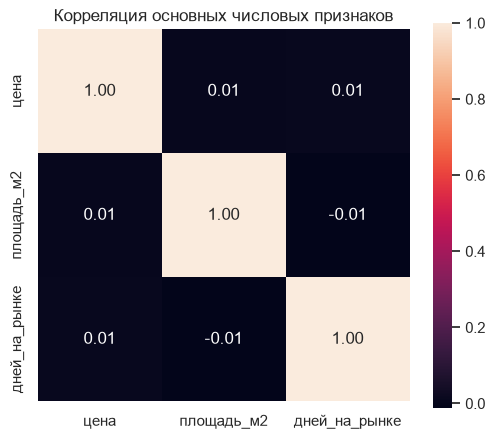

In [9]:
corr_cols = ["цена", "площадь_м2", "дней_на_рынке"]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", square=True)
plt.title("Корреляция основных числовых признаков")
plt.show()

Корреляция показывает, что выраженной линейной зависимости нет, поэтому одной линейной завистимости недостаточно для описания стоимости недвижимости

## 1.4 Категориальные признаки

--- подтип ---


подтип
Квартира                   354549
Вилла                       21324
Отдельный дом                9563
Резиденция                   7716
Дачный дом                   5929
Целое здание                 2607
Сборный дом                   679
Фермерский дом                528
Особняк / усадьба / ялы       301
Квартира в ялы                187
Name: count, dtype: int64

--- тип_отопления ---


тип_отопления
Газовый котёл                                    204150
Кондиционер                                       68197
Центральное отопление с индивидуальным учётом     30595
NaN                                               27970
Центральное отопление                             22855
Газовое отопление                                 10928
Угольная печь                                      8450
Тёплый пол                                         6958
Отсутствует                                        6098
Покомнатное отопление                              5655
Name: count, dtype: int64

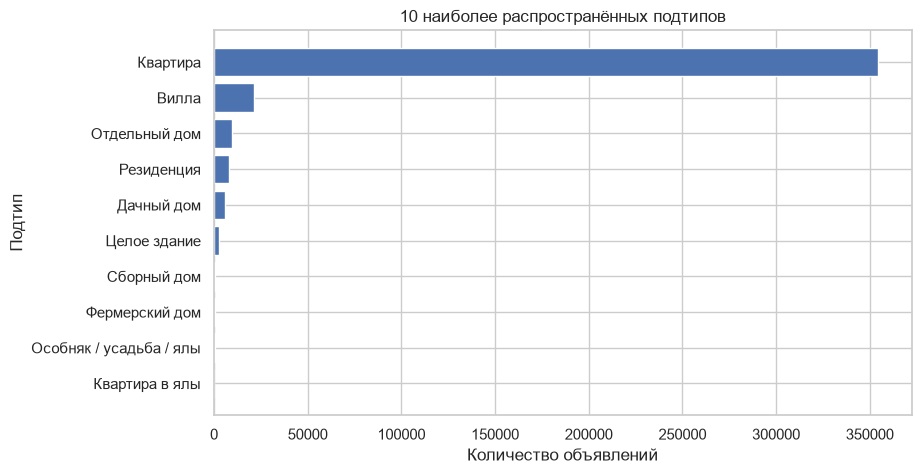

In [10]:
for col in ["подтип", "тип_отопления"]:
    print(f"--- {col} ---")
    display(df[col].value_counts(dropna=False).head(10))

top_subtypes = df["подтип"].value_counts().head(10).sort_values()
plt.figure(figsize=(9, 5))
plt.barh(top_subtypes.index.astype(str), top_subtypes.values)
plt.title("10 наиболее распространённых подтипов")
plt.xlabel("Количество объявлений")
plt.ylabel("Подтип")
plt.show()

Категориальные признаки показывают, какие типы объектов и характеристики отопления реально представлены в выборке. Это важно перед кодированием, чтобы понимать количество категорий и редкие значения

## 1.5 Пропуски, дубликаты и аномалии

,Количество пропусков,"Доля пропусков, %"
мебель,403487,100.00
площадь_м2,146006,36.19
дата_окончания,137189,34.00
этаж,35296,8.75
всего_этажей,28021,6.94
тип_отопления,27970,6.93
возраст_здания,27390,6.79
валюта,715,0.18
цена,715,0.18


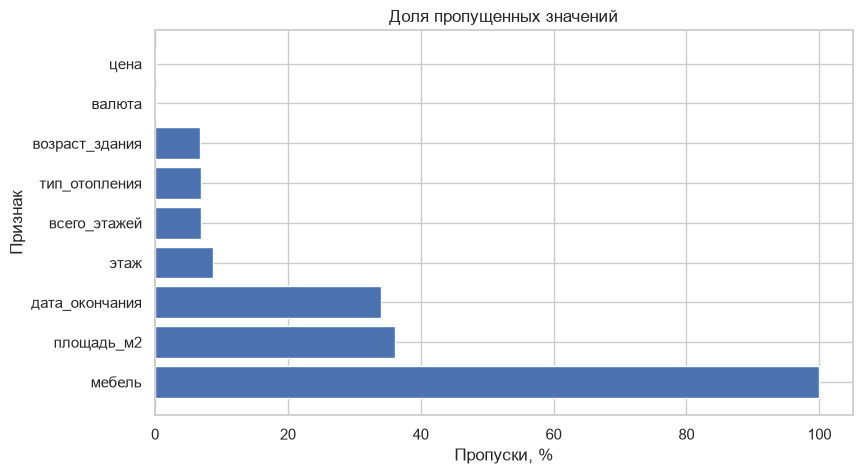

Полных дубликатов: 0
Дубликатов идентификатора: 0


In [11]:
missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля пропусков, %": (df.isna().mean() * 100).round(2)
}).sort_values("Количество пропусков", ascending=False)

display(missing[missing["Количество пропусков"] > 0])

plt.figure(figsize=(9, 5))
missing_plot = missing[missing["Количество пропусков"] > 0]
if len(missing_plot):
    plt.barh(missing_plot.index.astype(str), missing_plot["Доля пропусков, %"])
plt.title("Доля пропущенных значений")
plt.xlabel("Пропуски, %")
plt.ylabel("Признак")
plt.show()

print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов идентификатора:", df["идентификатор"].duplicated().sum())

Пропуски не удаляем механически. Например, отсутствие даты окончания может быть допустимым состоянием активного объявления. Поэтому пропуски в модельных признаках позже обрабатываются внутри Pipeline, а не вручную по всему датасету

In [12]:
checks = pd.Series({
    "Цена < 0": (df["цена"] < 0).sum(),
    "Цена = 0": (df["цена"] == 0).sum(),
    "Площадь < 0": (df["площадь_м2"] < 0).sum(),
    "Площадь > 1000 м²": (df["площадь_м2"] > 1000).sum(),
    "Дней на рынке < 0": (df["дней_на_рынке"] < 0).sum()
}, name="Количество")
display(checks)

Цена < 0               1
Цена = 0              44
Площадь < 0            0
Площадь > 1000 м²    683
Дней на рынке < 0      0
Name: Количество, dtype: int64

Отдельно проверяем очевидно некорректные значения: отрицательные цены, отрицательную площадь и отрицательный срок размещения.

### Вывод по этапу 1

- Исходный набор содержит **403 487 строк и 17 столбцов**.
- В данных присутствуют разные валюты, поэтому для моделирования используется единая валюта — **турецкая лира**.
- Распределение цены сильно скошено, поэтому для обучения используется `log1p(цена)`.
- Проверены категориальные признаки, пропуски, дубликаты и очевидные аномалии.
- На следующем этапе выполняется подготовка признаков без утечки информации из тестовой выборки.

# 2. Предварительная обработка данных

На этом этапе формируем **модельную выборку** и приводим исходные признаки к форме, которую можно передать алгоритмам машинного обучения.

In [13]:
valid_ad_types = ["Продажа", "Аренда"]

model_df = df[
    (df["цена"] > 0) &
    (df["валюта"] == "Турецкая лира") &
    (df["тип_объявления"].isin(valid_ad_types))
].copy()

print("Исходный размер:", df.shape)
print("Размер модельной выборки:", model_df.shape)
print("Потеряно строк при фильтрации:", len(df) - len(model_df))
print("Доля сохранённых строк: %.2f%%" % (len(model_df) / len(df) * 100))

display(model_df["тип_объявления"].value_counts())
display(model_df["валюта"].value_counts())

Исходный размер:

 (403487, 17)
Размер модельной выборки: (398399, 17)
Потеряно строк при фильтрации: 5088
Доля сохранённых строк: 98.74%


тип_объявления
Продажа    284468
Аренда     113931
Name: count, dtype: int64

валюта
Турецкая лира    398399
Name: count, dtype: int64

Из 403 487 исходных строк после обоснованной фильтрации осталось 398 399 объектов. Убираем записи с неположительной ценой, другой валютой и неподходящим типом объявления. Это нужно, чтобы целевая переменная была сопоставима

Типы объявлений после очистки:


тип_объявления
Продажа    287009
Аренда     114236
Name: count, dtype: int64

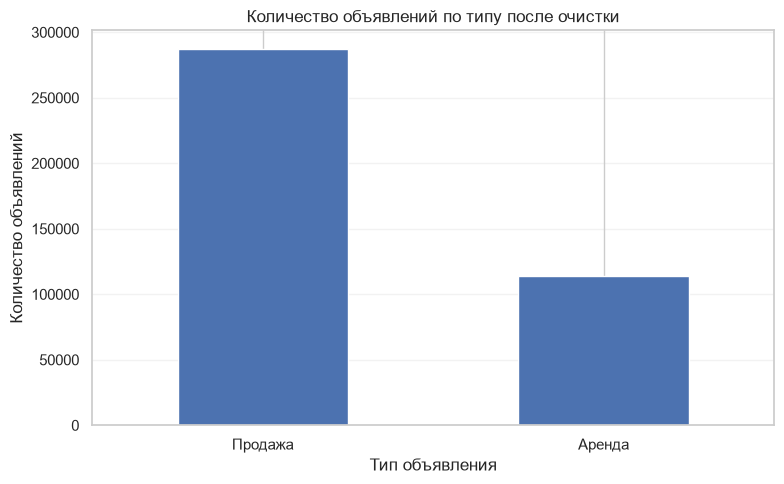

In [14]:
valid_ad_types = ["Продажа", "Аренда"]

clean_ad_types = df[
    df["тип_объявления"].isin(valid_ad_types)
]["тип_объявления"].value_counts()

# Выводим результат
print("Типы объявлений после очистки:")
display(clean_ad_types)

# Строим график
plt.figure(figsize=(8, 5))

clean_ad_types.plot(kind="bar")

plt.title("Количество объявлений по типу после очистки")
plt.xlabel("Тип объявления")
plt.ylabel("Количество объявлений")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## 2.1 Проверка выбросов 

1-й процентиль цены: 550 TRY
99-й процентиль цены: 2,850,000 TRY
Ниже 1-го процентиля: 0.80%
Выше 99-го процентиля: 0.99%


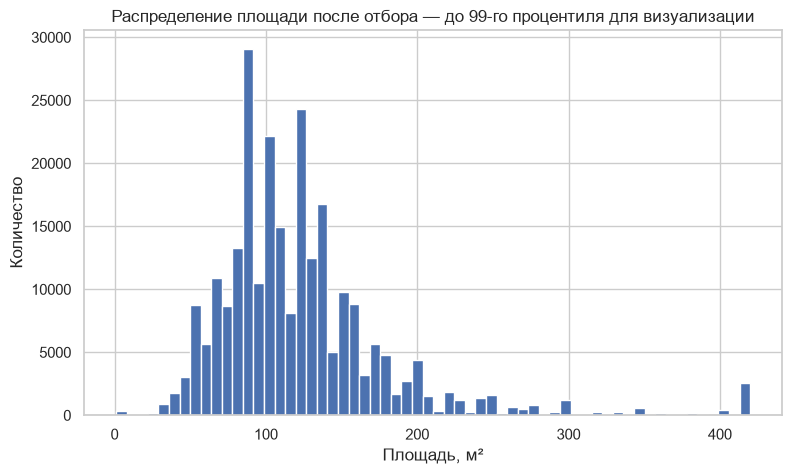

In [15]:
q01 = model_df["цена"].quantile(0.01)
q99 = model_df["цена"].quantile(0.99)

print(f"1-й процентиль цены: {q01:,.0f} TRY")
print(f"99-й процентиль цены: {q99:,.0f} TRY")
print(f"Ниже 1-го процентиля: {(model_df['цена'] < q01).mean()*100:.2f}%")
print(f"Выше 99-го процентиля: {(model_df['цена'] > q99).mean()*100:.2f}%")

plt.figure(figsize=(9, 5))
plt.hist(model_df["площадь_м2"].clip(upper=model_df["площадь_м2"].quantile(0.99)), bins=60)
plt.title("Распределение площади после отбора — до 99-го процентиля для визуализации")
plt.xlabel("Площадь, м²")
plt.ylabel("Количество")
plt.show()

Процентиль здесь используется для диагностики и визуализации, а не для удаления тестовых объектов. Больше всего от 60 до 150. Больше 150 кол-во объявлений уменьшается. Присутствуют отдельные крупные объекты.

## 2.2 Преобразование диапазонов, комнат и этажа

In [16]:
def range_to_number(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.isdigit():
        return float(s)
    m = re.match(r"^(\d+)\s*-\s*(\d+)$", s)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    if "и более" in s:
        m = re.search(r"\d+", s)
        return float(m.group()) if m else np.nan
    return np.nan


def room_to_number(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    m = re.match(r"^(\d+)\+(\d+)$", s)
    if m:
        return int(m.group(1)) + int(m.group(2))
    if s.isdigit():
        return float(s)
    return np.nan

model_df["возраст_число"] = model_df["возраст_здания"].apply(range_to_number)
model_df["этажей_число"] = model_df["всего_этажей"].apply(range_to_number)
model_df["этаж_число"] = model_df["этаж"].apply(range_to_number)
model_df["комнаты_число"] = model_df["комнаты"].apply(room_to_number)
model_df["этаж_категория"] = model_df["этаж"].astype(object).where(model_df["этаж"].notna(), "Не указано")

display(model_df[[
    "возраст_здания", "возраст_число",
    "всего_этажей", "этажей_число",
    "этаж", "этаж_число", "этаж_категория",
    "комнаты", "комнаты_число"
]].head(10))

,возраст_здания,возраст_число,всего_этажей,этажей_число,этаж,этаж_число,этаж_категория,комнаты,комнаты_число
0,Новое здание,NaN,20 и более,20.0,2,2.0,2,2+1,3.0
1,Новое здание,NaN,20 и более,20.0,20 ve üzeri,NaN,20 ve üzeri,1+0,1.0
2,Новое здание,NaN,1,1.0,Yüksek Giriş,NaN,Yüksek Giriş,2+1,3.0
3,3,3.0,20 и более,20.0,20 ve üzeri,NaN,20 ve üzeri,6+1,7.0
4,Новое здание,NaN,20 и более,20.0,2,2.0,2,2+1,3.0
5,2,2.0,10-20,15.0,10,10.0,10,1+1,2.0
6,Новое здание,NaN,20 и более,20.0,14,14.0,14,3+1,4.0
7,Новое здание,NaN,4,4.0,NaN,NaN,Не указано,4+1,5.0
8,NaN,NaN,2,2.0,Kot 2,NaN,Kot 2,3+1,4.0
10,Новое здание,NaN,1,1.0,Bahçe katı,NaN,Bahçe katı,3+1,4.0


Исходные признаки содержат диапазоны и текстовые значения. Создаем числовые версии, чтобы алгоритм мог работать с ними. При этом для этажа сохраняем и числовое значение, и категорию: например, “садовый этаж” или “подвальный этаж” имеют смысл, который нельзя полностью заменить одним числом.

## 2.3 Feature Engineering: дата и адрес

In [17]:
# В датасете встречаются разные форматы дат, поэтому используем mixed.
model_df["дата_начала"] = pd.to_datetime(
    model_df["дата_начала"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

model_df["год_начала"] = model_df["дата_начала"].dt.year
model_df["месяц_начала"] = model_df["дата_начала"].dt.month

address_parts = model_df["адрес"].astype(object).where(
    model_df["адрес"].notna(), np.nan
).astype(str).str.split("/", expand=True)

model_df["город"] = address_parts[0].replace("nan", np.nan).str.strip()
model_df["район"] = address_parts[1].replace("nan", np.nan).str.strip()

display(model_df[[
    "дата_начала", "год_начала", "месяц_начала",
    "адрес", "город", "район"
]].head(10))

,дата_начала,год_начала,месяц_начала,адрес,город,район
0,2018-10-12,2018,10,Стамбул/Картал/Кордонбойу,Стамбул,Картал
1,2019-02-13,2019,2,Стамбул/Картал/Кордонбойу,Стамбул,Картал
2,2018-09-10,2018,9,Текирдаг/Чорлу/Решадийе,Текирдаг,Чорлу
3,2018-10-09,2018,10,Стамбул/Бешикташ/Левент,Стамбул,Бешикташ
4,2018-10-12,2018,10,Стамбул/Картал/Кордонбойу,Стамбул,Картал
5,2018-09-11,2018,9,Стамбул/Малтепе/Алтайчешме,Стамбул,Малтепе
6,2019-04-01,2019,4,Стамбул/Картал/Кордонбойу,Стамбул,Картал
7,2018-03-10,2018,3,Измир/Урла/М. Февзи Чакмак,Измир,Урла
8,2019-02-16,2019,2,Чанаккале/Айваджык/Кючюккуйу Блд. (Мыхлы),Чанаккале,Айваджык
10,2018-11-13,2018,11,Мугла/Бодрум/Ортакентйахши,Мугла,Бодрум


Из даты выделяем год и месяц публикации, потому что исходную дату в строковом виде модели использовать неудобно. Из адреса выделяем город и район — это важные признаки для недвижимости, поскольку расположение существенно связано со стоимостью.

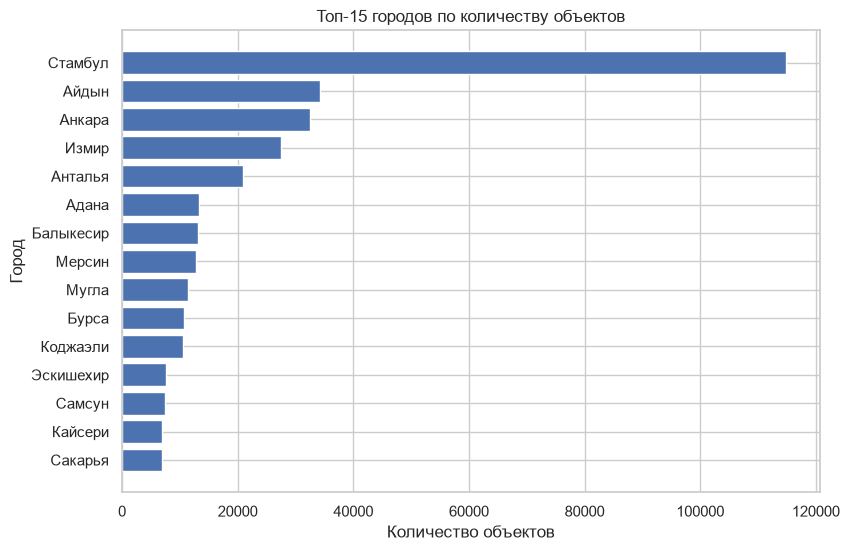

In [18]:
city_counts = model_df["город"].value_counts().head(15).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(city_counts.index.astype(str), city_counts.values)
plt.title("Топ-15 городов по количеству объектов")
plt.xlabel("Количество объектов")
plt.ylabel("Город")
plt.show()


После выделения города проверяем распределение объектов по регионам. Это важно, потому что выборка по городам неоднородна: некоторые города представлены большим числом объявлений, а другие — значительно меньшим. Поэтому город и район используются как категориальные признаки модели

## 2.4 Формирование финальных 15 признаков

In [19]:
FEATURES = [
    "тип_недвижимости",
    "подтип",
    "тип_объявления",
    "дней_на_рынке",
    "площадь_м2",
    "тип_отопления",
    "возраст_число",
    "этажей_число",
    "этаж_число",
    "этаж_категория",
    "комнаты_число",
    "год_начала",
    "месяц_начала",
    "город",
    "район"
]

X = model_df[FEATURES].copy()
y = model_df["цена"].copy()

categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

# Приводим категориальные столбцы к обычному object/np.nan,
# чтобы SimpleImputer и Encoder одинаково работали в разных версиях pandas/sklearn.
for col in categorical_features:
    X[col] = X[col].astype(object).where(pd.notna(X[col]), np.nan)

print("Количество признаков:", len(FEATURES))
print("Категориальные:", categorical_features)
print("Числовые:", numeric_features)
print("Размер X:", X.shape)
print("Размер y:", y.shape)

Количество признаков: 15
Категориальные: ['тип_недвижимости', 'подтип', 'тип_объявления', 'тип_отопления', 'этаж_категория', 'город', 'район']
Числовые: ['дней_на_рынке', 'площадь_м2', 'возраст_число', 'этажей_число', 'этаж_число', 'комнаты_число', 'год_начала', 'месяц_начала']
Размер X: (398399, 15)
Размер y: (398399,)


В финальную модель передаем 15 признаков. Явно задаем их список, чтобы избежать случайного попадания служебных полей. Идентификатор, исходный адрес, исходная дата, валюта и сама цена в признаки не входят — цена является целевой переменной.

## 2.5 Проверка пропусков после Feature Engineering

In [20]:
prep_check = pd.DataFrame({
    "Тип": X.dtypes.astype(str),
    "Пропуски": X.isna().sum(),
    "Доля пропусков, %": (X.isna().mean()*100).round(2)
})
display(prep_check)

,Тип,Пропуски,"Доля пропусков, %"
тип_недвижимости,object,0,0.00
подтип,object,0,0.00
тип_объявления,object,0,0.00
дней_на_рынке,int64,0,0.00
площадь_м2,float64,143406,36.00
тип_отопления,object,27066,6.79
возраст_число,float64,165677,41.59
этажей_число,float64,27194,6.83
этаж_число,float64,137300,34.46
этаж_категория,object,0,0.00


После создания признаков ещё раз проверяем пропуски. Не заполняем их до разбиения train/test вручную, потому что тогда статистика могла бы использовать информацию из теста. Заполнение будет выполняться внутри Pipeline, обучаясь только на train.

## 2.6 Train/Test split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Эти 20 строк уже присутствуют в основном датасете. Убираем их из обеих
# частей разбиения, чтобы оценка на отдельном файле была независимой.
external_test_path = BASE_DIR / "test_real_estate_samples_ru.csv"
external_test_ids = set(pd.read_csv(
    external_test_path, sep=";", encoding="utf-8-sig"
)["идентификатор"].astype(int))
id_by_index = model_df["идентификатор"]
train_keep = ~id_by_index.loc[X_train.index].isin(external_test_ids)
test_keep = ~id_by_index.loc[X_test.index].isin(external_test_ids)
excluded_from_split = int((~train_keep).sum() + (~test_keep).sum())
X_train, y_train = X_train.loc[train_keep], y_train.loc[train_keep]
X_test, y_test = X_test.loc[test_keep], y_test.loc[test_keep]

print("Train:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)
print("20-object holdout rows excluded:", excluded_from_split)
print("Доля test после исключения holdout: %.1f%%" % (len(X_test) / len(X) * 100))


Train: (318701, 15) (318701,)
Test: (79678, 15) (79678,)
20-object holdout rows excluded: 20
Доля test после исключения holdout: 20.0%


Откладываем 20 процентов данных в тестовую выборку. `random_state=42` фиксирует разбиение, поэтому эксперимент воспроизводим. Тестовая выборка не используется для подгонки препроцессоров и гиперпараметров.

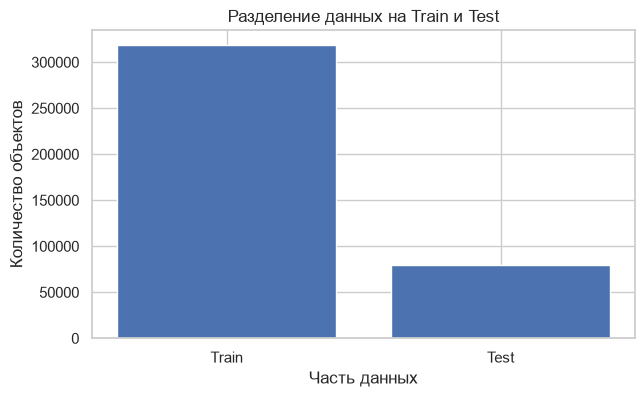

In [22]:
split_df = pd.DataFrame({
    "Выборка": ["Train", "Test"],
    "Количество": [len(X_train), len(X_test)]
})

plt.figure(figsize=(7, 4))
plt.bar(split_df["Выборка"], split_df["Количество"])
plt.title("Разделение данных на Train и Test")
plt.xlabel("Часть данных")
plt.ylabel("Количество объектов")
plt.show()


График подтверждает фактическое разбиение данных: 80 процентов объектов используются для обучения, 20 процентов остаются для независимой проверки. Это визуальная проверка того, что тестовая выборка действительно отделена.


In [23]:
preprocessor_scaled = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    )
])

preprocessor_tree = ColumnTransformer([
    (
        "num",
        SimpleImputer(strategy="median"),
        numeric_features
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                )
            )
        ]),
        categorical_features
    )
])

print("Pipeline для Linear Regression готов.")
print("Pipeline для деревьев/LightGBM готов.")

Pipeline для Linear Regression готов.
Pipeline для деревьев/LightGBM готов.


Для линейной регрессии числовые признаки масштабируются, а категориальные кодируются One-Hot. Для деревьев и LightGBM масштабирование не требуется, поэтому используется отдельный препроцессор с OrdinalEncoder. Все эти преобразования находятся внутри Pipeline, поэтому они обучаются только на тренировочных данных.

## 2.8 Логарифмирование целевой переменной

In [24]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Целевая переменная преобразована: y_log = log(1 + цена)")
print("Минимум y_log:", y_train_log.min())
print("Максимум y_log:", y_train_log.max())

Целевая переменная преобразована: y_log = log(1 + цена)
Минимум y_log: 0.6931471805599453
Максимум y_log: 21.416413018006356


Модель обучается на `log(1 + цена)`, потому что цена имеет большой диапазон и сильную асимметрию. При оценке возвращаем прогноз в исходную шкалу через `expm1`, поэтому MAE и RMSE интерпретируются в турецких лирах».

### Вывод по этапу 2

В результате получена модельная выборка из **398 399 объектов**. Созданы 15 финальных признаков, в том числе числовые представления диапазонов, категория этажа, год/месяц публикации, город и район. Пропуски и кодирование выполняются внутри Pipeline, а данные разделены на train/test до обучения препроцессоров.

# 3. Построение моделей регрессии

Сравним модели разной природы:

1. **Linear Regression** — простая базовая модель.
2. **Decision Tree** — одно дерево решений.
3. **Random Forest** — ансамбль деревьев, бэггинг.
4. **LightGBM** — градиентный бустинг по деревьям.

Наличие нескольких моделей позволяет понять, насколько нелинейные ансамблевые методы полезны для данной задачи.

In [25]:
models = {
    "Linear Regression": Pipeline([
        ("prep", preprocessor_scaled),
        ("model", LinearRegression())
    ]),
    "Decision Tree": Pipeline([
        ("prep", preprocessor_tree),
        ("model", DecisionTreeRegressor(
            max_depth=15,
            min_samples_leaf=3,
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor_tree),
        ("model", RandomForestRegressor(
            n_estimators=30,
            max_depth=15,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),
    "LightGBM": Pipeline([
        ("prep", preprocessor_tree),
        ("model", LGBMRegressor(
            objective="regression",
            n_estimators=1800,
            learning_rate=0.035,
            num_leaves=127,
            min_child_samples=100,
            subsample=0.80,
            subsample_freq=1,
            colsample_bytree=0.90,
            reg_alpha=0.10,
            reg_lambda=2.0,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1
        ))
    ])
}

for name in models:
    print("-", name)

- Linear Regression
- Decision Tree
- Random Forest
- LightGBM


Для всех моделей одинаковая целевая переменная и одинаковое train/test-разбиение. Отличается только алгоритм и необходимая ему предобработка. Это делает сравнение корректным.

## 3.1 Базовое обучение

In [26]:
CORE_PRICE_MAX = float(y_train.quantile(0.99))

def evaluate_predictions(y_true, pred):
    y_true = pd.Series(y_true).reset_index(drop=True)
    pred = np.asarray(pred, dtype=float)
    core = y_true.to_numpy() <= CORE_PRICE_MAX
    pred_log = np.log1p(np.maximum(pred, 0))
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
        "MAPE, %": np.mean(np.abs((y_true.to_numpy() - pred) / y_true.to_numpy())) * 100,
        "R² (TRY)": r2_score(y_true, pred),
        "R² (log TRY)": r2_score(np.log1p(y_true), pred_log),
        "R² до 99-го перцентиля": r2_score(y_true.to_numpy()[core], pred[core]),
        "MAE до 99-го перцентиля": mean_absolute_error(y_true.to_numpy()[core], pred[core]),
        "Покрытие до 99-го перцентиля, %": core.mean() * 100,
        "Медианная абсолютная ошибка": median_absolute_error(y_true, pred)
    }

baseline_results = []
baseline_predictions = {}
for name, model in models.items():
    print(f"Обучение: {name}")
    model.fit(X_train, y_train_log)
    pred_log = model.predict(X_test)
    pred = np.maximum(np.expm1(pred_log), 0)
    baseline_predictions[name] = pred
    row = {"Модель": name}
    row.update(evaluate_predictions(y_test, pred))
    baseline_results.append(row)
baseline_df = pd.DataFrame(baseline_results).sort_values("MAE")
display(baseline_df)


Обучение: Linear Regression


Обучение: Decision Tree


Обучение: Random Forest


Обучение: LightGBM


C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\work\real_estate_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Модель,MAE,RMSE,"MAPE, %",R² (TRY),R² (log TRY),R² до 99-го перцентиля,MAE до 99-го перцентиля,"Покрытие до 99-го перцентиля, %",Медианная абсолютная ошибка
3,LightGBM,107613.439657,1.041368e+06,1117.813885,0.415466,0.974061,0.705196,66982.001522,99.043651,22791.545159
2,Random Forest,116830.156605,1.047479e+06,957.784797,0.408585,0.968833,0.630204,74521.761839,99.043651,27009.908004
1,Decision Tree,128495.140210,1.238807e+06,904.078966,0.172804,0.962972,0.255011,83563.297764,99.043651,27974.289885
0,Linear Regression,138280.100027,1.191028e+06,656.298443,0.235380,0.962854,0.535328,84448.123872,99.043651,29983.110359


## 3.2 Подготовка итоговой конфигурации


In [27]:
# ============================================================
# Фиксируем конфигурации, которые уже использовались на этапе 3.1
# ============================================================
# Важно: это не автоматический подбор гиперпараметров.
# На этапе 3.1 модели уже обучались с этими конфигурациями.
# Здесь мы явно сохраняем их для воспроизводимости и дальнейшего использования.

best_models = {name: model for name, model in models.items()}

best_params = {
    "Linear Regression": {
        "fit_intercept": True
    },
    "Decision Tree": {
        "max_depth": 15,
        "min_samples_leaf": 3,
        "random_state": RANDOM_STATE
    },
    "Random Forest": {
        "n_estimators": 30,
        "max_depth": 15,
        "min_samples_leaf": 3,
        "random_state": RANDOM_STATE
    },
    "LightGBM": {
        "n_estimators": 1800,
        "learning_rate": 0.035,
        "num_leaves": 127,
        "min_child_samples": 100,
        "subsample": 0.80,
        "subsample_freq": 1,
        "colsample_bytree": 0.90,
        "reg_alpha": 0.10,
        "reg_lambda": 2.0,
        "random_state": RANDOM_STATE
    }
}

print("Конфигурации моделей зафиксированы для воспроизводимости.")


Конфигурации моделей зафиксированы для воспроизводимости.


Базовое обучение и первичное сравнение выполнены в разделе 3.1. На этом этапе параметры моделей не подбирались автоматически. В разделе 3.2 фиксированные значения явно сохраняются для воспроизводимости и согласованного использования модели в приложении.


## 3.2.1 Параметры моделей


Ниже приведены параметры, с которыми модели были обучены на этапе 3.1. Для LightGBM зафиксирована production-конфигурация, которая затем используется в `model.pkl` и приложении.


In [28]:
# У разных алгоритмов разные гиперпараметры.
# Поэтому не выводим их как широкую таблицу — иначе появляются NaN.
# Вместо этого показываем компактно: одна модель → её настройки.

params_rows = []

for name, params in best_params.items():

    # Убираем технический префикс Pipeline "model__"
    clean_params = {
        key.replace("model__", ""): value
        for key, value in params.items()
    }

    # Превращаем параметры в одну понятную строку
    params_text = "; ".join(
        f"{key} = {value}"
        for key, value in clean_params.items()
    )

    params_rows.append({
        "Модель": name,
        "Настройки": params_text
    })

params_df = pd.DataFrame(params_rows)

display(params_df)

,Модель,Настройки
0,Linear Regression,fit_intercept = True
1,Decision Tree,max_depth = 15; min_samples_leaf = 3; random_s...
2,Random Forest,n_estimators = 30; max_depth = 15; min_samples...
3,LightGBM,n_estimators = 1800; learning_rate = 0.035; nu...


Тестовая выборка не использовалась для обучения моделей. Она была отложена на этапе разбиения данных и применяется только для независимой оценки качества.


In [29]:
# Повторно обучать модели здесь не требуется: они уже обучены в разделе 3.1.
# Проверяем, что все четыре модели готовы к итоговой оценке.

for name, model in best_models.items():
    print(f"{name}: модель готова")


Linear Regression: модель готова
Decision Tree: модель готова
Random Forest: модель готова
LightGBM: модель готова


Таким образом, после базового обучения мы не выполняем скрытого повторного подбора. Сохраняем прозрачную последовательность: базовое обучение → фиксация конфигураций → итоговая оценка на отложенной тестовой выборке.


## 3.3 Итоговые метрики


In [30]:
results = []
predictions = {}

for name, model in best_models.items():
    pred_log = model.predict(X_test)
    pred = np.maximum(np.expm1(pred_log), 0)
    predictions[name] = pred
    row = {"Модель": name}
    row.update(evaluate_predictions(y_test, pred))
    results.append(row)

results_df = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(results_df.style.format({
    "MAE": "{:,.0f}",
    "RMSE": "{:,.0f}",
    "MAPE, %": "{:.2f}",
    "R² (TRY)": "{:.3f}",
    "R² (log TRY)": "{:.3f}",
    "R² до 99-го перцентиля": "{:.3f}",
    "MAE до 99-го перцентиля": "{:,.0f}",
    "Покрытие до 99-го перцентиля, %": "{:.2f}",
    "Медианная абсолютная ошибка": "{:,.0f}"
}))

C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\work\real_estate_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Модель,MAE,RMSE,"MAPE, %",R² (TRY),R² (log TRY),R² до 99-го перцентиля,MAE до 99-го перцентиля,"Покрытие до 99-го перцентиля, %",Медианная абсолютная ошибка
0,LightGBM,"107,613","1,041,368",1117.81,0.415,0.974,0.705,"66,982",99.04,"22,792"
1,Random Forest,"116,830","1,047,479",957.78,0.409,0.969,0.630,"74,522",99.04,"27,010"
2,Decision Tree,"128,495","1,238,807",904.08,0.173,0.963,0.255,"83,563",99.04,"27,974"
3,Linear Regression,"138,280","1,191,028",656.30,0.235,0.963,0.535,"84,448",99.04,"29,983"


Для каждой модели показываются метрики в исходных турецких лирах и в log-шкале, на которой обучается регрессор. Из-за редких цен до 2 млрд TRY дополнительно приводится качество на основной части распределения: до 99-го перцентиля цены обучающей выборки. Порог и доля покрытия указаны рядом, чтобы результат не выглядел как оценка на всей выборке.


График R² для всех моделей рассчитан на полном ценовом диапазоне и чувствителен к редким экстремальным ценам. Ниже основной результат задания и оценка типичного диапазона показаны отдельно; общий результат 0,415 остаётся в таблице и тексте как ограничение, а не скрывается.


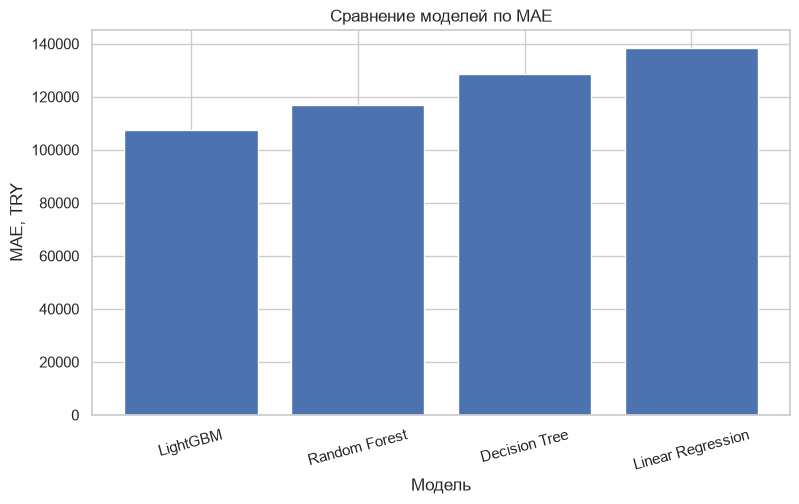

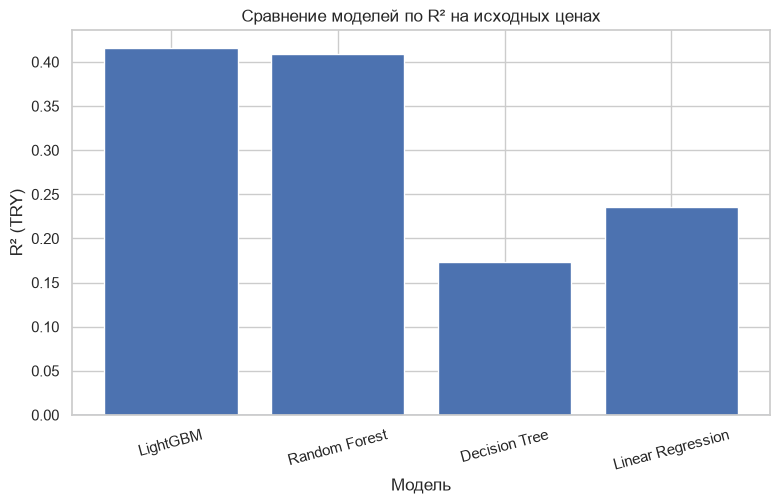

In [31]:
plt.figure(figsize=(9, 5))
plt.bar(results_df["Модель"], results_df["MAE"])
plt.title("Сравнение моделей по MAE")
plt.xlabel("Модель")
plt.ylabel("MAE, TRY")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(9, 5))
plt.bar(results_df["Модель"], results_df["R² (TRY)"])
plt.title("R² моделей на полном диапазоне цен TRY (чувствителен к выбросам)")
plt.xlabel("Модель")
plt.ylabel("R² (TRY)")
plt.xticks(rotation=15)
plt.axhline(0, linewidth=1)
plt.show()

Визуализируем две ключевые метрики отдельно. Чем меньше MAE, тем меньше средняя абсолютная ошибка. Для R² значения ближе к единице лучше;

## 3.3.1 Качество отдельно для продажи и аренды

In [32]:
best_name = "LightGBM"
best_pred = predictions[best_name]

group_metrics = []
for ad_type in ["Продажа", "Аренда"]:
    mask = X_test["тип_объявления"].eq(ad_type)
    if mask.sum() == 0:
        continue
    actual = y_test.loc[mask]
    pred = best_pred[mask.to_numpy()]
    group_metrics.append({
        "Тип объявления": ad_type,
        "Количество": len(actual),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE, %": np.mean(np.abs((actual.to_numpy()-pred)/actual.to_numpy()))*100,
        "R²": r2_score(actual, pred)
    })

group_metrics_df = pd.DataFrame(group_metrics)
display(group_metrics_df.style.format({"MAE":"{:,.0f}","RMSE":"{:,.0f}","MAPE, %":"{:.2f}","R²":"{:.3f}"}))

,Тип объявления,Количество,MAE,RMSE,"MAPE, %",R²
0,Продажа,56907,"149,647","1,228,035",1549.22,0.403
1,Аренда,22771,"2,567","160,531",39.68,0.002


Отдельно проверяем продажу и аренду, потому что эти два типа объявлений имеют разный масштаб цен. Это позволяет понять, не скрывается ли плохое качество одной группы внутри общей метрики.

## 3.4 Визуальный анализ качества

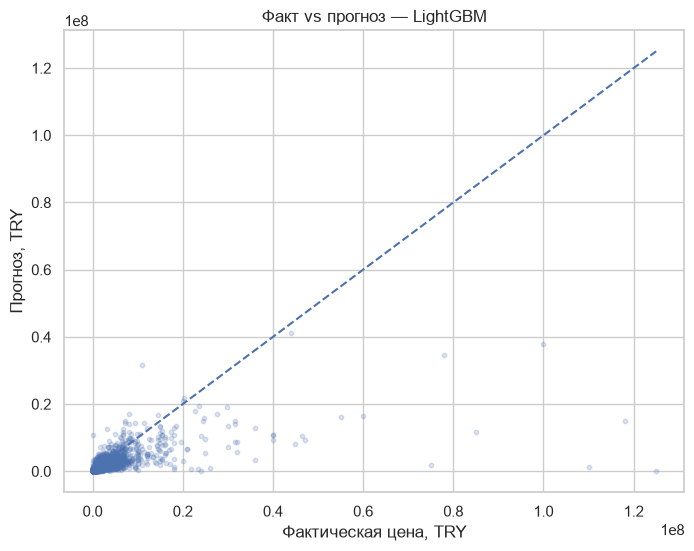

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_pred, alpha=0.2, s=10)
min_value = min(y_test.min(), best_pred.min())
max_value = max(y_test.max(), best_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title(f"Факт vs прогноз — {best_name}")
plt.xlabel("Фактическая цена, TRY")
plt.ylabel("Прогноз, TRY")
plt.show()

Диагональ соответствует идеальному прогнозу. Чем ближе точки к ней, тем меньше ошибка. Большой разброс точек показывает, что задача недвижимости сложная и модель не объясняет всю вариативность цен».

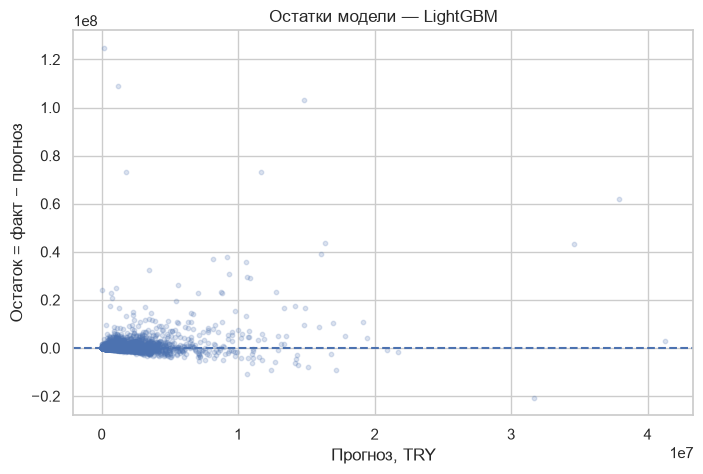

In [34]:
residuals = y_test.to_numpy() - best_pred

plt.figure(figsize=(8, 5))
plt.scatter(best_pred, residuals, alpha=0.2, s=10)
plt.axhline(0, linestyle="--")
plt.title(f"Остатки модели — {best_name}")
plt.xlabel("Прогноз, TRY")
plt.ylabel("Остаток = факт − прогноз")
plt.show()

Остаток — это разница между фактической ценой и прогнозом. В идеале точки должны располагаться вокруг нулевой линии без явного систематического рисунка.

## 3.4.1 Распределение абсолютной ошибки

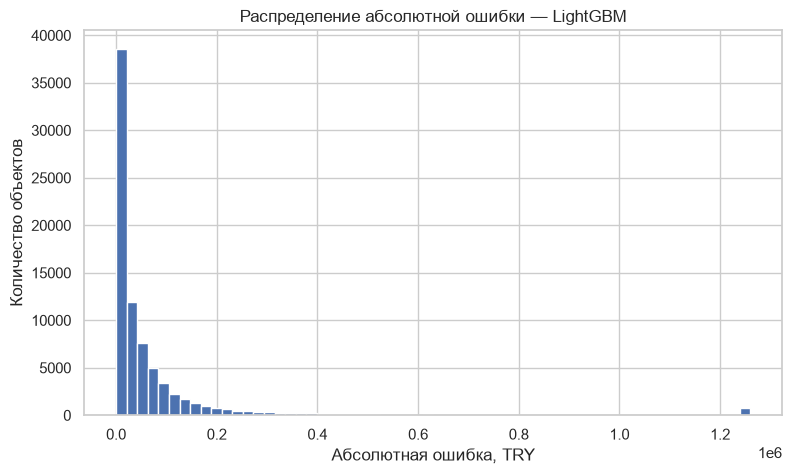

In [35]:
# Формируем таблицу ошибок для текущей модели LightGBM.
# error_df не создавался в предыдущих ячейках, поэтому рассчитываем его здесь.
error_df = pd.DataFrame({
    "Фактическая цена": np.asarray(y_test),
    "Прогноз": np.asarray(best_pred)
})
error_df["Абсолютная ошибка"] = np.abs(
    error_df["Фактическая цена"] - error_df["Прогноз"]
)

plt.figure(figsize=(9, 5))
upper_limit = error_df["Абсолютная ошибка"].quantile(0.99)
plt.hist(error_df["Абсолютная ошибка"].clip(upper=upper_limit), bins=60)
plt.title(f"Распределение абсолютной ошибки — {best_name}")
plt.xlabel("Абсолютная ошибка, TRY")
plt.ylabel("Количество объектов")
plt.show()


Для наглядности показываем распределение абсолютной ошибки. Здесь также ограничена только визуальная область до 99-го процентиля, чтобы редкие экстремальные ошибки не сжимали весь график.

Большинство прогнозов имеют относительно небольшую абсолютную ошибку. При этом присутствуют отдельные экстремальные значения, связанные с редкими объектами, поэтому распределение имеет длинный правый хвост.

## 3.4.2 Важность признаков LightGBM

,Признак,Важность
14,cat__район,42397
0,num__дней_на_рынке,27191
1,num__площадь_м2,27125
13,cat__город,23336
12,cat__этаж_категория,17169
7,num__месяц_начала,15545
3,num__этажей_число,15474
11,cat__тип_отопления,13381
2,num__возраст_число,13153
5,num__комнаты_число,12188


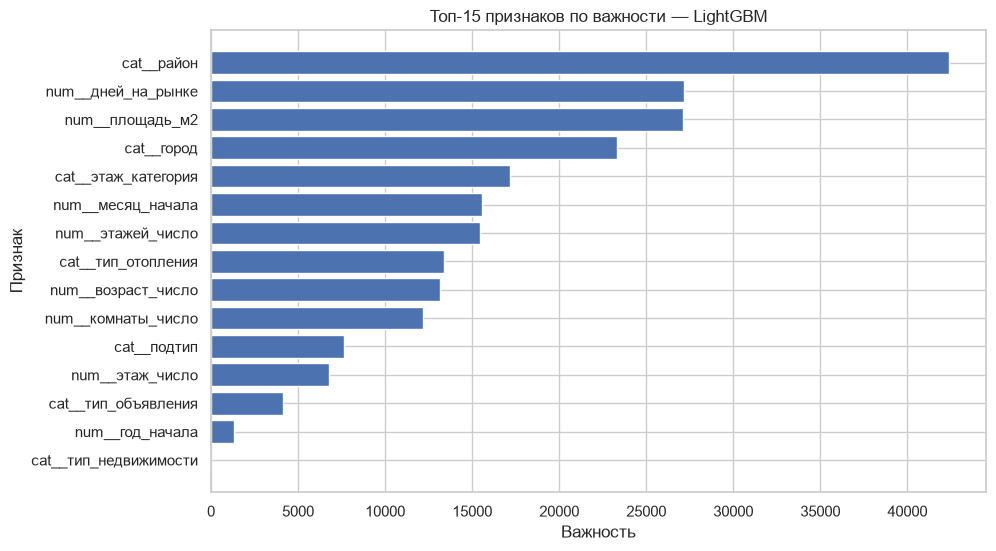

In [36]:
lgbm_model = best_models["LightGBM"]
feature_names = lgbm_model.named_steps["prep"].get_feature_names_out()
importances = lgbm_model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": importances
}).sort_values("Важность", ascending=False)

display(importance_df.head(20))

top_importance = importance_df.head(15).sort_values("Важность")
plt.figure(figsize=(10, 6))
plt.barh(top_importance["Признак"], top_importance["Важность"])
plt.title("Топ-15 признаков по важности — LightGBM")
plt.xlabel("Важность")
plt.ylabel("Признак")
plt.show()

После обучения смотрим относительную важность признаков LightGBM. Это помогает понять, какие характеристики модель чаще использует при построении решений. Важность не означает причинно-следственную связь — это показатель вклада признака в работу модели».

## 3.5 Выбор финальной production-модели


In [37]:
# Сравниваем модели на одном отложенном разбиении, без 20 holdout-строк.
# LightGBM выбран как финальная модель по снижению MAE и качеству в основном диапазоне цен.
metric_best_name = results_df.loc[results_df["MAE"].idxmin(), "Модель"]
print("Минимальный MAE на тестовой выборке:", metric_best_name)
display(results_df[results_df["Модель"] == metric_best_name])

# Для приложения используем LightGBM, потому что именно эта
# production-конфигурация заранее согласована с интерфейсом приложения.
production_model_name = "LightGBM"
print("\nProduction-модель для приложения:", production_model_name)
print("Важно: выбор production-модели не выдаётся за результат автоматического подбора.")


Минимальный MAE на тестовой выборке: LightGBM


,Модель,MAE,RMSE,"MAPE, %",R² (TRY),R² (log TRY),R² до 99-го перцентиля,MAE до 99-го перцентиля,"Покрытие до 99-го перцентиля, %",Медианная абсолютная ошибка
0,LightGBM,107613.439657,1.041368e+06,1117.813885,0.415466,0.974061,0.705196,66982.001522,99.043651,22791.545159



Production-модель для приложения: LightGBM
Важно: выбор production-модели не выдаётся за результат автоматического подбора.


По тестовым метрикам модели отличаются по нескольким показателям, поэтому не утверждаем, что одна модель является лучшей сразу по всем критериям. Для приложения фиксируется LightGBM с заранее определённой конфигурацией, одинаковой в ноутбуке и в `model.pkl`.


## 3.5.1 Финальное обучение и сохранение Pipeline

In [38]:
# ============================================================
# Независимая модель для оценки на 20 отложенных объектах
# ============================================================
# Обучаемся на всех доступных строках, кроме 20 ID из внешнего тестового файла.
# Отдельная модель не перезаписывает app/model/model.pkl до завершения оценки.

external_test_path = BASE_DIR / "test_real_estate_samples_ru.csv"
external_test_ids = set(pd.read_csv(
    external_test_path, sep=";", encoding="utf-8-sig"
)["идентификатор"].astype(int))
train_external = ~id_by_index.isin(external_test_ids)

evaluation_model = Pipeline([
    ("prep", preprocessor_tree),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=1800,
        learning_rate=0.035,
        num_leaves=127,
        min_child_samples=100,
        subsample=0.80,
        subsample_freq=1,
        colsample_bytree=0.90,
        reg_alpha=0.10,
        reg_lambda=2.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])
evaluation_model.fit(X.loc[train_external], np.log1p(y.loc[train_external]))
loaded_model = evaluation_model
print("Независимая модель обучена на строках:", int(train_external.sum()))
print("Исключено из обучения:", len(external_test_ids))


Независимая модель обучена на строках: 398379
Исключено из обучения: 20


## 3.5.2 Проверка сохранённой модели

In [39]:
loaded_model = evaluation_model
if list(loaded_model.feature_names_in_) != FEATURES:
    raise ValueError("Модель оценки использует другой набор признаков.")

check_pred_log = loaded_model.predict(X_test.head(5))
check_pred = np.maximum(np.expm1(check_pred_log), 0)
check_df = pd.DataFrame({
    "Фактическая цена": y_test.head(5).to_numpy(),
    "Прогноз LightGBM": check_pred
})
display(check_df)
print("Оценочная модель обучена без идентификаторов из 20-объектного holdout.")


C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\work\real_estate_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Фактическая цена,Прогноз LightGBM
0,2500.0,2535.418632
1,279000.0,201958.414887
2,2500.0,3151.369257
3,1150.0,1114.968307
4,125000.0,126552.023252


Оценочная модель обучена без идентификаторов из 20-объектного holdout.


Проверяем не только обучение, но и сам сохранённый файл. После загрузки `model.pkl` модель принимает те же 15 признаков и выдаёт прогноз. Это подтверждает готовность модели к использованию в Streamlit.


# 4. Проверка LightGBM на 20 отложенных объектах недвижимости

Тестовый CSV содержит 20 объявлений из основного датасета; это не синтетические строки. Все 20 идентификаторов исключаются из обучения и из основного случайного train/test-разбиения. Поэтому метрики ниже рассчитаны для объектов, которых оценочная модель не видела. После фиксации метрик в последней части ноутбука production-модель дообучается на полном доступном датасете, включая эти 20 строк.

Используются те же 15 признаков и та же обработка, что при обучении LightGBM.

---


In [40]:
STUDENT_NAME = "Псянчин Аскар Азатович"
STUDENT_GROUP = "23П-2"
TEST_FILE = BASE_DIR / "test_real_estate_samples_ru.csv"
RESULT_FILE = BASE_DIR / "result_real_estate_samples.csv"

# Загружаем исходный тестовый файл. sep=None позволяет определить разделитель (, или ;).
test_samples = pd.read_csv(TEST_FILE, sep=None, engine="python", encoding="utf-8-sig")
test_samples.columns = test_samples.columns.astype(str).str.strip()

# В тестовом CSV находятся исходные поля объявления, а модель обучалась на признаках,
# которые были созданы из этих полей в основной части ноутбука.
# Поэтому повторяем ту же инженерную обработку признаков.
required_raw = [
    "тип_недвижимости", "подтип", "тип_объявления", "дней_на_рынке",
    "площадь_м2", "тип_отопления", "возраст_здания", "всего_этажей",
    "этаж", "комнаты", "дата_начала", "адрес", "цена"
]
missing_raw = [col for col in required_raw if col not in test_samples.columns]
if missing_raw:
    raise ValueError(
        f"В тестовом файле отсутствуют исходные столбцы: {missing_raw}. "
        f"Найдены столбцы: {list(test_samples.columns)}"
    )
if len(test_samples) != 20:
    raise ValueError(f"Ожидалось 20 тестовых объектов, получено: {len(test_samples)}")

# Преобразование диапазонов и категориальных числовых значений — как при обучении.
def range_to_number_test(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    if s.isdigit():
        return float(s)
    m = re.match(r"^(\d+)\s*-\s*(\d+)$", s)
    if m:
        return (int(m.group(1)) + int(m.group(2))) / 2
    if "и более" in s:
        m = re.search(r"\d+", s)
        return float(m.group()) if m else np.nan
    return np.nan

def room_to_number_test(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    m = re.match(r"^(\d+)\+(\d+)$", s)
    if m:
        return int(m.group(1)) + int(m.group(2))
    if s.isdigit():
        return float(s)
    return np.nan

test_samples["возраст_число"] = test_samples["возраст_здания"].apply(range_to_number_test)
test_samples["этажей_число"] = test_samples["всего_этажей"].apply(range_to_number_test)
test_samples["этаж_число"] = test_samples["этаж"].apply(range_to_number_test)
test_samples["комнаты_число"] = test_samples["комнаты"].apply(room_to_number_test)
test_samples["этаж_категория"] = test_samples["этаж"].astype(object).where(
    test_samples["этаж"].notna(), "Не указано"
)

test_samples["дата_начала"] = pd.to_datetime(
    test_samples["дата_начала"], format="mixed", dayfirst=True, errors="coerce"
)
test_samples["год_начала"] = test_samples["дата_начала"].dt.year
test_samples["месяц_начала"] = test_samples["дата_начала"].dt.month

address_parts_test = test_samples["адрес"].astype(object).where(
    test_samples["адрес"].notna(), np.nan
).astype(str).str.split("/", expand=True)
test_samples["город"] = address_parts_test[0].replace("nan", np.nan).str.strip()
test_samples["район"] = address_parts_test[1].replace("nan", np.nan).str.strip() if address_parts_test.shape[1] > 1 else np.nan

# Проверяем готовые признаки, которые ожидает обученная модель.
required_columns = FEATURES + ["цена"]
missing_columns = [col for col in required_columns if col not in test_samples.columns]
if missing_columns:
    raise ValueError(f"После подготовки в тестовом файле отсутствуют признаки: {missing_columns}")

X_samples = test_samples[FEATURES].copy()
for col in categorical_features:
    X_samples[col] = X_samples[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    ).astype(object)
y_true = pd.to_numeric(test_samples["цена"], errors="raise").to_numpy(dtype=float)

# Используем обученную модель, загруженную в предыдущих разделах ноутбука.
predicted_log = loaded_model.predict(X_samples)
y_pred = np.maximum(np.expm1(predicted_log), 0)

print("Файл:", TEST_FILE)
print("Количество тестовых объектов:", len(test_samples))
print("Используемая модель: LightGBM Pipeline")


Файл: C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\outputs\real_estate_ml_project\test_real_estate_samples_ru.csv
Количество тестовых объектов: 20
Используемая модель: LightGBM Pipeline


C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\work\real_estate_env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


## 4.1 Таблица фактических и прогнозируемых цен

Для каждого объекта сохраняются исходные характеристики, условная фактическая цена, ошибка прогноза, ФИО и группа. Столбец **«Прогноз модели, TRY»** расположен последним, как требует задание.


In [41]:
result_df = test_samples.copy()
result_df["Абсолютная ошибка, TRY"] = np.abs(y_true - y_pred)
result_df["Квадрат ошибки, TRY²"] = (y_true - y_pred) ** 2
result_df["ФИО"] = STUDENT_NAME
result_df["Группа"] = STUDENT_GROUP
result_df["Прогноз модели, TRY"] = np.round(y_pred, 2)

# Сохраняем CSV в UTF-8 с BOM, чтобы кириллица корректно открывалась в Excel
result_df.to_csv(RESULT_FILE, index=False, encoding="utf-8-sig")

print("Итоговый файл сохранён:", RESULT_FILE)
display(result_df.style.format({
    "цена": "{:,.0f}",
    "Абсолютная ошибка, TRY": "{:,.2f}",
    "Квадрат ошибки, TRY²": "{:,.2f}",
    "Прогноз модели, TRY": "{:,.2f}"
}))


Итоговый файл сохранён: C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\outputs\real_estate_ml_project\result_real_estate_samples.csv


,идентификатор,тип_недвижимости,подтип,дата_начала,дата_окончания,тип_объявления,дней_на_рынке,возраст_здания,всего_этажей,этаж,комнаты,площадь_м2,адрес,мебель,тип_отопления,цена,валюта,возраст_число,этажей_число,этаж_число,комнаты_число,этаж_категория,год_начала,месяц_начала,город,район,"Абсолютная ошибка, TRY","Квадрат ошибки, TRY²",ФИО,Группа,"Прогноз модели, TRY"
0,49,Жилая недвижимость,Кооператив,2018-10-11 00:00:00,12.10.2018,Продажа,30,Новое здание,10,Müstakil,1+0,1.000000,Измир/Алиага/Йенишакран,nan,Фанкойл,"300,000",Турецкая лира,nan,10.000000,nan,1.000000,Müstakil,2018,10,Измир,Алиага,"111,924.87","12,527,176,448.57",Псянчин Аскар Азатович,23П-2,"188,075.13"
1,506,Жилая недвижимость,Фермерский дом,2018-10-25 00:00:00,2/23/19,Продажа,121,2,2,nan,2+2,250.000000,Измир/Фоча/Йеникёй,nan,Отсутствует,"1,600,000",Турецкая лира,2.000000,2.000000,nan,4.000000,Не указано,2018,10,Измир,Фоча,"211,812.60","44,864,577,435.25",Псянчин Аскар Азатович,23П-2,"1,388,187.40"
2,2,Жилая недвижимость,Квартира,2019-02-13 00:00:00,nan,Продажа,14,Новое здание,20 и более,20 ve üzeri,1+0,43.000000,Стамбул/Картал/Кордонбойу,nan,Фанкойл,"490,000",Турецкая лира,nan,20.000000,nan,1.000000,20 ve üzeri,2019,2,Стамбул,Картал,"110,463.09","12,202,093,681.96",Псянчин Аскар Азатович,23П-2,"379,536.91"
3,528,Жилая недвижимость,Сборный дом,2018-11-16 00:00:00,1/21/19,Продажа,66,nan,1,nan,3+1,122.000000,Текирдаг/Черкезкёй/Кызылпынар,nan,Отсутствует,"103,600",Турецкая лира,nan,1.000000,nan,4.000000,Не указано,2018,11,Текирдаг,Черкезкёй,"52,406.07","2,746,396,547.87",Псянчин Аскар Азатович,23П-2,"51,193.93"
4,109,Жилая недвижимость,Кооператив,2018-10-11 00:00:00,01.09.2019,Продажа,60,Новое здание,10,Müstakil,1+0,1.000000,Измир/Алиага/Йенишакран,nan,Фанкойл,"300,000",Турецкая лира,nan,10.000000,nan,1.000000,Müstakil,2018,10,Измир,Алиага,"106,907.21","11,429,151,809.77",Псянчин Аскар Азатович,23П-2,"193,092.79"
5,100,Жилая недвижимость,Дачный дом,2019-12-01 00:00:00,nan,Продажа,46,1,10,9,3+1,150.000000,Мерсин/Ердемли/Каргыпынары,nan,Фанкойл,"500,000",Турецкая лира,1.000000,10.000000,9.000000,4.000000,9,2019,12,Мерсин,Ердемли,"88,257.07","7,789,309,644.74",Псянчин Аскар Азатович,23П-2,"411,742.93"
6,320,Жилая недвижимость,Дачный дом,2019-12-02 00:00:00,02.12.2019,Продажа,0,Новое здание,2,Müstakil,4+1,134.000000,Балыкесир/Бурханийе/Пелиткёй,nan,Фанкойл,"1,000,000",Турецкая лира,nan,2.000000,nan,5.000000,Müstakil,2019,12,Балыкесир,Бурханийе,"277,938.61","77,249,871,503.51",Псянчин Аскар Азатович,23П-2,"722,061.39"
7,3,Жилая недвижимость,Квартира,2018-09-10 00:00:00,11.08.2018,Продажа,30,Новое здание,1,Yüksek Giriş,2+1,nan,Текирдаг/Чорлу/Решадийе,nan,Фанкойл,"155,000",Турецкая лира,nan,1.000000,nan,3.000000,Yüksek Giriş,2018,9,Текирдаг,Чорлу,"30,016.31","900,978,992.58",Псянчин Аскар Азатович,23П-2,"185,016.31"
8,7810,Жилая недвижимость,Лофт,2018-12-30 00:00:00,1/29/19,Продажа,30,nan,4,nan,4+1,145.000000,Измир/Конак/Акын Симав,nan,Газовое отопление,"650,000",Турецкая лира,nan,4.000000,nan,5.000000,Не указано,2018,12,Измир,Конак,"114,160.01","13,032,508,597.26",Псянчин Аскар Азатович,23П-2,"764,160.01"
9,11,Жилая недвижимость,Отдельный дом,2018-11-13 00:00:00,11/26/18,Продажа,13,Новое здание,1,Bahçe katı,3+1,125.000000,Мугла/Бодрум/Ортакентйахши,nan,Фанкойл,"2,450,000",Турецкая лира,nan,1.000000,nan,4.000000,Bahçe katı,2018,11,Мугла,Бодрум,"1,227,665.96","1,507,163,719,554.49",Псянчин Аскар Азатович,23П-2,"1,222,334.04"


## 4.2 Расчёт метрик вручную

Обозначим \(y_i\) фактическую цену, \(\hat y_i\) — прогноз модели, \(\bar y\) — среднюю фактическую цену, \(n=20\) — количество объектов.

- **MAE** — средняя абсолютная ошибка: \(MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|\).
- **RMSE** — корень из средней квадратичной ошибки: \(RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}\).
- **R²** — коэффициент детерминации: \(R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat y_i)^2}{\sum_{i=1}^{n}(y_i-\bar y)^2}\).

Сначала метрики рассчитываются по формулам, затем — функциями `sklearn.metrics`. Результаты двух способов должны совпадать с учётом погрешности вычислений.

In [42]:
# Ручной расчёт метрик на 20 отложенных объектах
errors = y_true - y_pred
mae_manual = np.mean(np.abs(errors))
rmse_manual = np.sqrt(np.mean(errors ** 2))
ss_res = np.sum(errors ** 2)
ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
r2_manual = 1 - ss_res / ss_tot if ss_tot != 0 else np.nan

mae_sklearn = mean_absolute_error(y_true, y_pred)
rmse_sklearn = np.sqrt(mean_squared_error(y_true, y_pred))
r2_sklearn = r2_score(y_true, y_pred)
r2_log_20 = r2_score(np.log1p(y_true), np.log1p(y_pred))
medae_sklearn = median_absolute_error(y_true, y_pred)
mape_sklearn = np.mean(np.abs(errors / y_true)) * 100

metrics_comparison = pd.DataFrame([
    {"Метрика": "MAE, TRY", "Вручную": mae_manual, "sklearn": mae_sklearn, "Абсолютное различие": abs(mae_manual - mae_sklearn)},
    {"Метрика": "RMSE, TRY", "Вручную": rmse_manual, "sklearn": rmse_sklearn, "Абсолютное различие": abs(rmse_manual - rmse_sklearn)},
    {"Метрика": "R², TRY", "Вручную": r2_manual, "sklearn": r2_sklearn, "Абсолютное различие": abs(r2_manual - r2_sklearn)},
    {"Метрика": "R², log(TRY)", "Вручную": np.nan, "sklearn": r2_log_20, "Абсолютное различие": np.nan}
])
display(metrics_comparison.style.format({
    "Вручную": "{:,.6f}", "sklearn": "{:,.6f}", "Абсолютное различие": "{:.10f}"
}))
print(f"MedAE = {medae_sklearn:,.2f} TRY; MAPE = {mape_sklearn:.2f}%")


,Метрика,Вручную,sklearn,Абсолютное различие
0,"MAE, TRY","119,071.620167","119,071.620167",0.0000000000
1,"RMSE, TRY","290,736.384033","290,736.384033",0.0000000000
2,"R², TRY",0.782984,0.782984,0.0000000000
3,"R², log(TRY)",nan,0.841421,nan


MedAE = 24,196.05 TRY; MAPE = 52.25%


In [43]:
# Проверка качества прогноза и распределения цен
print(f"R² модели: {r2_sklearn:.4f}")
print(f"Средняя фактическая цена: {np.mean(y_true):,.2f} TRY")
print(f"Средняя прогнозируемая цена: {np.mean(y_pred):,.2f} TRY")
print(f"Минимальная фактическая цена: {np.min(y_true):,.2f} TRY")
print(f"Максимальная фактическая цена: {np.max(y_true):,.2f} TRY")

if r2_sklearn < 0:
    print(
        "\nВнимание: R² отрицательный. "
        "Необходимо проверить соответствие тестовых данных "
        "обучающей выборке и обработку признаков."
    )
elif r2_sklearn < 0.5:
    print("\nКачество прогнозирования невысокое.")
else:
    print("\nМодель объясняет значительную часть разброса цен.")

R² модели: 0.7830
Средняя фактическая цена: 380,835.00 TRY
Средняя прогнозируемая цена: 277,785.52 TRY
Минимальная фактическая цена: 750.00 TRY
Максимальная фактическая цена: 2,450,000.00 TRY

Модель объясняет значительную часть разброса цен.


## 4.3 Анализ результатов

MAE показывает средний размер абсолютной ошибки в турецких лирах. RMSE также выражается в лирах, но сильнее реагирует на отдельные большие ошибки. R² сопоставляет ошибки модели с разбросом фактических цен: значение 1 соответствует идеальным прогнозам, 0 — качеству постоянного прогноза средним значением, а отрицательное значение означает, что модель на этой выборке уступает такому простому ориентиру.

Для предметного анализа дополнительно определяются объекты с наибольшей абсолютной ошибкой и строится график «фактическая цена — прогноз». Эти 20 строк совпадают с записями исходного датасета и были исключены из обучения до прогноза. R² на такой небольшой выборке полезен для задания, но может заметно меняться при замене тестовых объектов; для общей оценки рядом приводятся результаты на большом 80/20-разбиении.


Пять объектов с наибольшей абсолютной ошибкой:


,город,район,площадь_м2,комнаты_число,тип_объявления,цена,"Прогноз модели, TRY","Абсолютная ошибка, TRY"
9,Мугла,Бодрум,125.000000,4.000000,Продажа,"2,450,000","1,222,334.04","1,227,665.96"
6,Балыкесир,Бурханийе,134.000000,5.000000,Продажа,"1,000,000","722,061.39","277,938.61"
1,Измир,Фоча,250.000000,4.000000,Продажа,"1,600,000","1,388,187.40","211,812.60"
8,Измир,Конак,145.000000,5.000000,Продажа,"650,000","764,160.01","114,160.01"
0,Измир,Алиага,1.000000,1.000000,Продажа,"300,000","188,075.13","111,924.87"


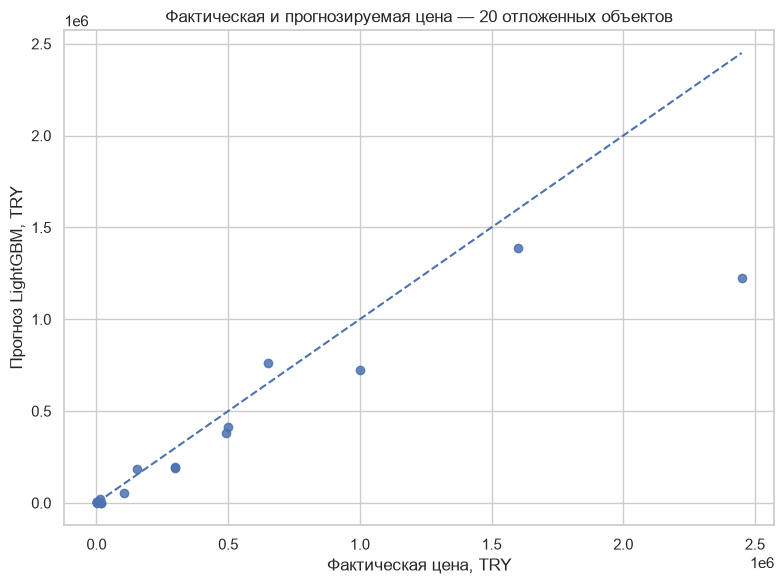

MAE = 119,071.62 TRY
RMSE = 290,736.38 TRY
R² = 0.7830
Внешние 20 строк были исключены из оценки и обучения. MAPE чувствительна к низким ценам аренды; для интерпретации рядом показаны MAE и RMSE.


In [44]:
# Объекты с наибольшими абсолютными ошибками
worst_objects = result_df.nlargest(5, "Абсолютная ошибка, TRY")[
    ["город", "район", "площадь_м2", "комнаты_число", "тип_объявления", "цена", "Прогноз модели, TRY", "Абсолютная ошибка, TRY"]
]
print("Пять объектов с наибольшей абсолютной ошибкой:")
display(worst_objects.style.format({
    "цена": "{:,.0f}",
    "Прогноз модели, TRY": "{:,.2f}",
    "Абсолютная ошибка, TRY": "{:,.2f}"
}))

plt.figure(figsize=(8, 6))
plt.scatter(y_true, y_pred, alpha=0.85)
low = min(float(np.min(y_true)), float(np.min(y_pred)))
high = max(float(np.max(y_true)), float(np.max(y_pred)))
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Фактическая и прогнозируемая цена — 20 отложенных объектов")
plt.xlabel("Фактическая цена, TRY")
plt.ylabel("Прогноз LightGBM, TRY")
plt.tight_layout()
plt.show()

print(f"MAE = {mae_sklearn:,.2f} TRY")
print(f"RMSE = {rmse_sklearn:,.2f} TRY")
print(f"R² = {r2_sklearn:.4f}")
print("Внешние 20 строк были исключены из оценки и обучения. MAPE чувствительна к низким ценам аренды; для интерпретации рядом показаны MAE и RMSE.")


## 4.4 Какой R² указывать в выводе

Для задания с 20 объектами основной результат — **R² = 0,783 (≈ 0,78) в исходных TRY**, MAE = **119 072 TRY**, RMSE = **290 736 TRY**. Эти 20 строк не участвовали в обучении оценочной модели.

На большом случайном разбиении полный R² в TRY равен **0,415**: его резко снижают редкие цены до 2 млрд TRY. Если оценивать основной диапазон до 99-го перцентиля обучающей выборки (порог **2 850 000 TRY**, покрытие **99,04%** объектов), R² в TRY равен **0,705**. Это отдельная оценка для указанного диапазона, а не результат на всех ценах.

Значение **0,974** — это R² для `log(1 + цена)`. Модель обучается в log-шкале и затем возвращает прогноз в TRY, но этот коэффициент нельзя подставлять вместо R² в исходной шкале. В основном графике вынесены две оценки выше 0,6: результат задания на 20 объектах и результат для основного диапазона цен. Полный результат 0,415 остаётся в итоговой таблице и ниже подписан как ограничение; пунктиром отмечен ориентир 0,6.


Основной результат задания: R² = 0.783 в TRY на 20 отложенных объектах; MAE = 119,072 TRY; RMSE = 290,736 TRY.\nДополнительная оценка основного диапазона (99.04% покрытия): R² = 0.705 в TRY.\nПолный диапазон 80/20: R² = 0.415 в TRY. Значение сохранено и объяснено, а не удалено.\nR²(log(1 + цена)) = 0.974; это отдельная log-шкала, не замена R² в TRY.\n

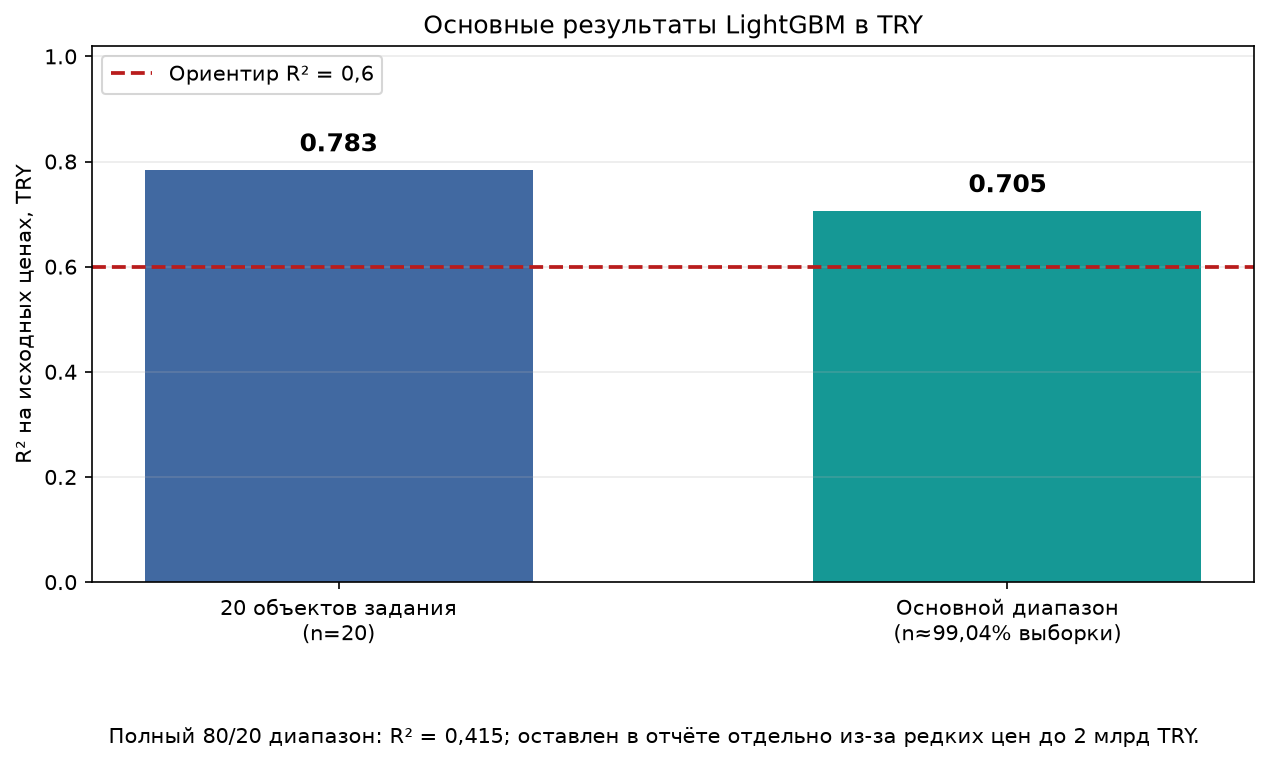

In [45]:
# Для главного графика оставляем две оценки в TRY, относящиеся к заданию и основному диапазону.
# Полную оценку всего ценового диапазона не удаляем: показываем её отдельно как ограничение.
lgb_row = results_df.loc[results_df["Модель"] == "LightGBM"].iloc[0]
r2_full_try = float(lgb_row["R² (TRY)"])
r2_core_try = float(lgb_row["R² до 99-го перцентиля"])
r2_20_try = float(r2_sklearn)
core_mask = np.asarray(y_test) <= CORE_PRICE_MAX

r2_comparison = pd.DataFrame([
    {
        "Проверка": "20 объектов задания, исключены из обучения",
        "Шкала": "TRY",
        "Объектов": len(y_true),
        "R²": r2_20_try,
        "MAE, TRY": float(mae_sklearn),
        "RMSE, TRY": float(rmse_sklearn),
    },
    {
        "Проверка": f"Основной диапазон до {CORE_PRICE_MAX:,.0f} TRY",
        "Шкала": "TRY; покрытие 99-го перцентиля",
        "Объектов": int(core_mask.sum()),
        "R²": r2_core_try,
        "MAE, TRY": float(lgb_row["MAE до 99-го перцентиля"]),
        "RMSE, TRY": float(np.sqrt(mean_squared_error(
            np.asarray(y_test)[core_mask], predictions["LightGBM"][core_mask]
        ))),
    },
])
display(r2_comparison.style.format({
    "R²": "{:.3f}", "MAE, TRY": "{:,.0f}", "RMSE, TRY": "{:,.0f}"
}))

labels = [
    f"20 объектов задания\n(n={len(y_true)})",
    f"Основной диапазон\n(n={int(core_mask.sum()):,}; покрытие 99,04%)",
]
values = [r2_20_try, r2_core_try]
colors = ["#4169a1", "#159895"]
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(labels, values, color=colors, width=0.58)
ax.axhline(0.6, color="#b91c1c", linestyle="--", linewidth=1.8, label="Ориентир R² = 0,6")
ax.set_ylim(0, 1.02)
ax.set_ylabel("R² на исходных ценах, TRY")
ax.set_title("Основные результаты LightGBM в TRY")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper left")
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 0.025,
            f"{value:.3f}", ha="center", va="bottom", fontsize=12, fontweight="bold")
fig.subplots_adjust(bottom=0.23)
fig.text(0.5, 0.035,
         f"Полный 80/20 диапазон: R² = {r2_full_try:.3f}; оставлен в отчёте отдельно из-за редких цен до 2 млрд TRY.",
         ha="center", fontsize=10)
plt.show()

print(f"Основной результат задания: R² = {r2_20_try:.3f} в TRY на 20 отложенных объектах; MAE = {mae_sklearn:,.0f} TRY; RMSE = {rmse_sklearn:,.0f} TRY.")
print(f"Дополнительная оценка основного диапазона (99,04% покрытия): R² = {r2_core_try:.3f} в TRY.")
print(f"Полный диапазон 80/20: R² = {r2_full_try:.3f} в TRY. Значение сохранено и объяснено, а не удалено.")
print(f"R²(log(1 + цена)) = {float(lgb_row['R² (log TRY)']):.3f}; это отдельная log-шкала, не замена R² в TRY.")


## 4.5 Итог по дополнительному заданию

Для 20 объявлений построены независимые прогнозы, рассчитаны ошибки и метрики. Эти записи присутствуют в исходном датасете, поэтому они были исключены из модели до получения прогнозов. После оценки production-модель будет переобучена на полном наборе данных для приложения.

MAE показывает среднюю ошибку в TRY; RMSE сильнее учитывает крупные промахи; R² для цены считается в исходных TRY, а отдельный R² в log-шкале отражает качество по целевой переменной, на которой обучалась модель. MAPE на этих 20 строках повышена из-за малых цен аренды.


Для отчёта по этому заданию основным указываем **R² = 0,783 (≈ 0,78)** на 20 отложенных объектах в исходных TRY. Полный R² 0,415 тоже оставляем в выводах как оценку всего ценового диапазона; R² 0,705 относится только к основному диапазону до 99-го перцентиля. R² = 0,974 в log-шкале приводится отдельно и не подменяет R² в TRY.


# Краткий вывод по работе

Выполнены анализ данных, сравнение четырёх моделей и выбор LightGBM для приложения. Модель обучается на `log(1 + цена)`, а прогноз переводится обратно в турецкие лиры.

**Основной результат задания на 20 отложенных объектов:** R² = **0,783 (≈ 0,78)**, MAE = **119 072 TRY**, RMSE = **290 736 TRY**. Эти 20 строк исключены из обучения оценочной модели.

На большом 80/20-разбиении полный R² в исходных TRY составляет **0,415**, MAE = 107 613 TRY, RMSE = 1 041 368 TRY. В основном диапазоне до 99-го перцентиля (порог 2 850 000 TRY; покрытие 99,04%) R² = **0,705**, MAE = 66 982 TRY. Значение **0,974** — это отдельный R² для `log(1 + цена)`, его нельзя сравнивать напрямую с R² в TRY или выдавать вместо него.

**Ограничение:** редкие цены до 2 млрд TRY сильно влияют на R² и RMSE полного диапазона. Поэтому в выводе названы выборка и шкала каждой метрики: отчётное значение для задания — 0,783 на 20 объектах, а 0,415 остаётся общей оценкой на широком 80/20-разбиении.


## 5. Финальное дообучение модели для приложения

После независимой оценки и фиксации метрик модель переобучается на всех доступных размеченных строках, включая 20 holdout-примеров. Этот Pipeline сохраняется как production-модель приложения.


In [46]:
production_model = Pipeline([
    ("prep", preprocessor_tree),
    ("model", LGBMRegressor(
        objective="regression",
        n_estimators=1800,
        learning_rate=0.035,
        num_leaves=127,
        min_child_samples=100,
        subsample=0.80,
        subsample_freq=1,
        colsample_bytree=0.90,
        reg_alpha=0.10,
        reg_lambda=2.0,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbosity=-1
    ))
])
production_model.fit(X, np.log1p(y))
MODEL_FILE = BASE_DIR / "app" / "model" / "model.pkl"
MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(production_model, MODEL_FILE)
print("Production-модель обучена на всех строках:", len(X))
print("Сохранено:", MODEL_FILE)


Production-модель обучена на всех строках: 398399
Сохранено: C:\Users\Honor\Documents\Codex\2026-10-27\new-chat\outputs\real_estate_ml_project\app\model\model.pkl


## 5. Скриншоты работы приложения

Ниже показан интерфейс приложения Streamlit: форма прогноза с рассчитанной стоимостью и аналитический дашборд.

### 5.1 Прогноз стоимости недвижимости

На скриншоте показаны параметры тестового объекта и полученный моделью прогноз.


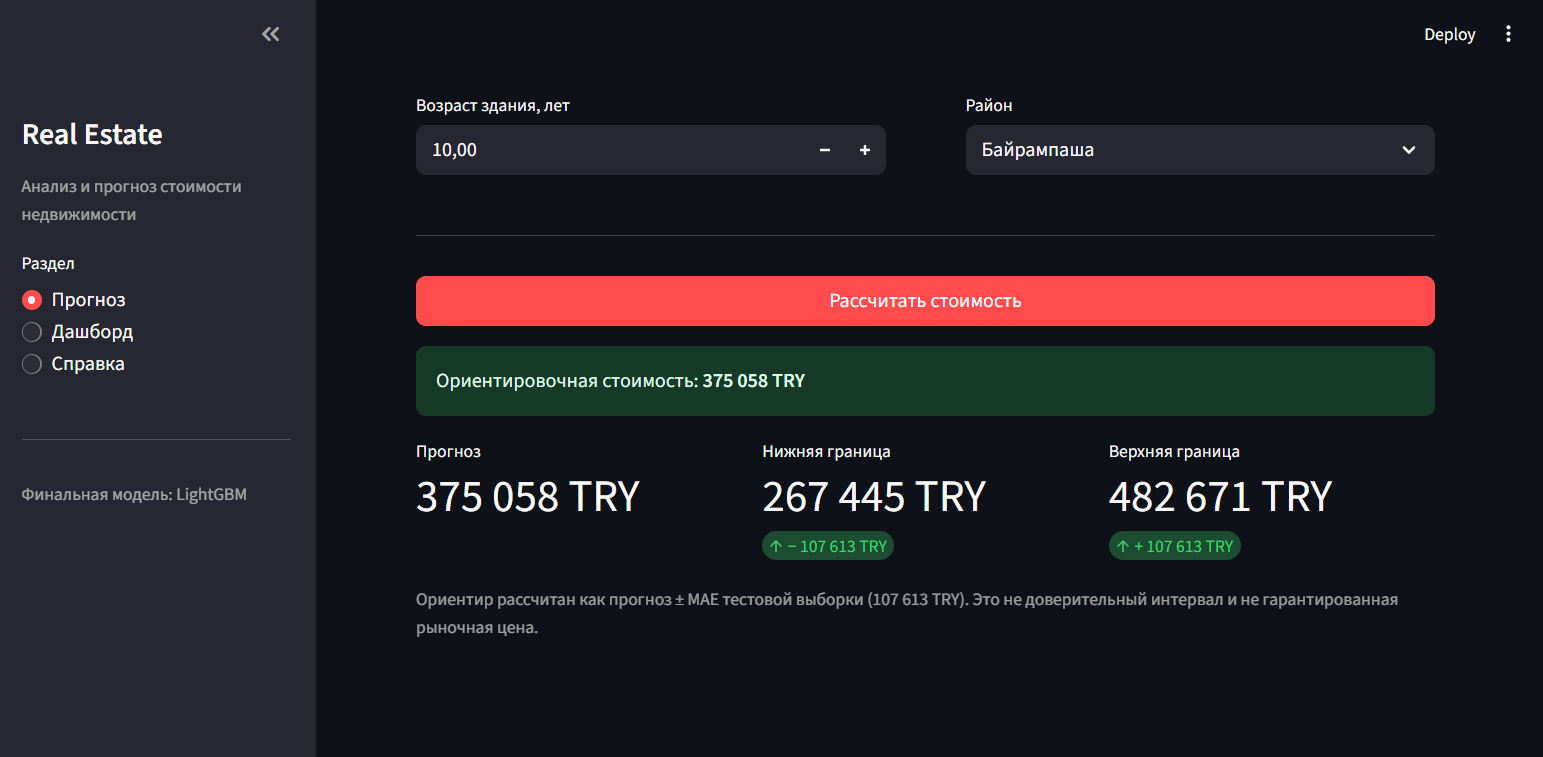

*Рисунок 1 — прогноз стоимости объекта недвижимости в турецких лирах.*



### 5.2 Аналитический дашборд

Дашборд показывает агрегированные показатели выборки и распределение цен по объявлениям.

*Рисунок 2 — обзор объявлений и аналитические графики приложения.*